In [2]:
import  pandas  as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot  as plt
import scipy.stats as stats
import datetime as dt

In [4]:
cust = pd.read_csv("D:\\Analytic_X_lab\\Python\\Assigment\\Python Foundation Case Study 2 - Credit Card Case Study\\Case Study 2 - Credit Card Case Study\\Customer Acqusition.csv")

In [6]:
spend  = pd.read_csv("D:\\Analytic_X_lab\\Python\\Assigment\\Python Foundation Case Study 2 - Credit Card Case Study\\Case Study 2 - Credit Card Case Study\\spend.csv") 

In [7]:
repayment = pd.read_csv("D:\\Analytic_X_lab\\Python\\Assigment\\Python Foundation Case Study 2 - Credit Card Case Study\\Case Study 2 - Credit Card Case Study\\Repayment.csv")

In [8]:
cust.head(1)

,No,Customer,Age,City,Product,Limit,Company,Segment
0,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed


In [22]:
cust.shape

(100, 8)

In [9]:
spend.head(1)

,Sl No:,Customer,Month,Type,Amount
0,1,A1,12-Jan-04,JEWELLERY,485470.8


In [23]:
spend.shape

(1500, 5)

In [11]:
repayment.head(5)

,SL No:,Customer,Month,Amount,Unnamed: 4
0,NaN,A1,12-Jan-04,495414.75,NaN
1,2.0,A1,3-Jan-04,245899.02,NaN
2,3.0,A1,15-Jan-04,259490.06,NaN
3,4.0,A1,25-Jan-04,437555.12,NaN
4,5.0,A1,17-Jan-05,165972.88,NaN


In [24]:
repayment.shape

(1523, 5)

In [161]:
spend_c = spend.merge(cust, on="Customer", how="left", suffixes=("", "_cust"))
repay_c = repayment.merge(cust, on="Customer", how="left", suffixes=("", "_cust"))
print(spend_c.shape, repay_c.shape)   # ab ~1500 aur ~1523 rows aani chahiye

(1500, 12) (1523, 12)


In [163]:
repay_c.head(2)

,SL No:,Customer,Month,Amount,Unnamed: 4,No,Age,City,Product,Limit,Company,Segment
0,NaN,A1,12-Jan-04,495414.75,NaN,1.0,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
1,2.0,A1,3-Jan-04,245899.02,NaN,1.0,76.0,BANGALORE,Gold,500000.0,C1,Self Employed


In [164]:
spend_c.drop(["No"],axis=1,inplace=True)
repay_c.drop(["Unnamed: 4"],axis=1,inplace=True)


In [165]:
spend_c.columns

Index(['Sl No:', 'Customer', 'Month', 'Type', 'Amount', 'Age', 'City',
       'Product', 'Limit', 'Company', 'Segment'],
      dtype='object')

In [166]:
# a. In case age is less than 18, replace it with mean of age values.
spend_c.loc[spend_c["Age"] < 18 ,"Age"] = spend_c["Age"].mean()
repay_c.loc[repay_c["Age"] < 18 ,"Age"] = repay_c["Age"].mean()

In [167]:
spend_c.columns

Index(['Sl No:', 'Customer', 'Month', 'Type', 'Amount', 'Age', 'City',
       'Product', 'Limit', 'Company', 'Segment'],
      dtype='object')

In [198]:
# b. In case spend amount is more than the limit, replace it with 50% of that customer’s limit. 
#(customer’s limit provided in acquisition table is the per transaction limit on his card
spend_c["Amount"] = np.where (spend_c['Amount']  > spend_c["Limit"],spend_c["Limit"]/2,spend_c["Amount"])

In [170]:
# c. Incase the repayment amount is more than the limit, replace the repayment with the limit.
repay_c["Amount"] = np.where(repay_c["Amount"] > repay_c["Limit"] ,repay_c["Limit"] , repay_c["Amount"])

# 2. From the above dataset create the following summaries:


In [172]:
#a. How many distinct customers exist?
print("There are ",repay_c["Customer"].nunique(),"distinct customers exist.")
print("There are ",spend_c["Customer"].nunique(),"distinct customers exist.")

There are  100 distinct customers exist.
There are  100 distinct customers exist.


In [174]:
spend_c.columns

Index(['Sl No:', 'Customer', 'Month', 'Type', 'Amount', 'Age', 'City',
       'Product', 'Limit', 'Company', 'Segment'],
      dtype='object')

In [175]:
#b. How many distinct categories exist?
d = spend_c[["Segment","City","Product","Type"]].columns
for i in d:
    print(f'Categories of {i} is : ')
    print(final[i].unique())
    print()

Categories of Segment is : 
['Self Employed' 'Salaried_Pvt' 'Govt' 'Normal Salary' 'Salaried_MNC']

Categories of City is : 
['BANGALORE' 'PATNA' 'CHENNAI' 'CALCUTTA' 'COCHIN' 'BOMBAY' 'DELHI'
 'TRIVANDRUM']

Categories of Product is : 
['Gold' 'Silver' 'Platimum']

Categories of Type is : 
['JEWELLERY' 'PETRO' 'CLOTHES' 'FOOD' 'CAMERA' 'SANDALS' 'CAR' 'BIKE'
 'AUTO' 'SHOPPING' 'AIR TICKET' 'BUS TICKET' 'TRAIN TICKET' 'RENTAL'
 'MOVIE TICKET']



In [178]:
# c. What is the average monthly spend by customers?
spend_c["Month"] = pd.to_datetime(spend_c["Month"] , format="%d-%b-%y")
spend_c["Mo_spend"] = spend_c["Month"].dt.month
spend_c.groupby("Mo_spend")["Amount"].sum().reset_index().round(2)

,Mo_spend,Amount
0,1,51571793.96
1,2,36000252.50
2,3,30455215.99
3,4,20255389.10
4,5,31841036.26
5,6,10194112.96
6,7,6985726.35
7,8,6961903.04
8,9,5927531.59
9,10,3668499.92


Index(['SL No:', 'Customer', 'Month', 'Amount', 'No', 'Age', 'City', 'Product',
       'Limit', 'Company', 'Segment'],
      dtype='object')

In [179]:
# d. What is the average monthly repayment by customers?
repay_c["Month"] = pd.to_datetime(repay_c["Month"] , format="%d-%b-%y")
repay_c.groupby(repay_c["Month"].dt.to_period("M"))["Amount"].sum().reset_index().round(2)

,Month,Amount
0,2004-01,44792020.72
1,2004-02,3391537.65
2,2004-03,2666519.22
3,2004-04,5268979.74
4,2004-05,3782759.91
5,2004-09,1902816.41
6,2004-11,1788398.63
7,2005-01,4894040.25
8,2005-02,25491800.20
9,2005-04,3634903.56


In [88]:
# e. If the monthly rate of interest is 2.9%, what is the profit for the bank for each month? 
# (Profit is defined as interest earned on Monthly Profit. Monthly Profit = Monthly repayment – Monthly spend.
# Interest is earned only on positive profits and not on negative amounts
final["Monthly_Profit"] = final["Amount_repayment"] - final["Amount_spend"]
p = final.loc[final["Monthly_Profit"] > 0 ].copy()
p.groupby(p["Month_repayment"].dt.to_period("M"))["Monthly_Profit"].sum().reset_index().round(1)
p["Monthly_rate_of_intererest"] = p["Monthly_Profit"] * 2.9 / 100
p.groupby(final["Month_repayment"].dt.to_period("M"))["Monthly_rate_of_intererest"].mean().reset_index().round(1)

,Month_repayment,Monthly_rate_of_intererest
0,2004-01,2466.4
1,2004-02,1828.0
2,2004-03,3401.1
3,2004-04,2832.0
4,2004-05,2438.1
5,2004-09,2407.4
6,2004-11,1995.2
7,2005-01,3070.5
8,2005-02,2624.5
9,2005-04,1779.4


In [181]:
#f. What are the top 5 product types?
spend_c.groupby("Type")["Amount"].sum().reset_index()\
                                    .sort_values("Amount",ascending = False , ignore_index= True).round(2).head(5)



,Type,Amount
0,CAMERA,173067.12
1,MOVIE TICKET,171077.62
2,CAR,170262.25
3,BUS TICKET,164443.79
4,RENTAL,155929.33


In [182]:
# g. Which city is having maximum spend?
spend_c.groupby("City")["Amount"].sum().reset_index().sort_values("Amount",ascending = False , ignore_index=True).round(2).iloc[0][0]


C:\Users\Asus\AppData\Local\Temp\ipykernel_8412\536538320.py:2: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  spend_c.groupby("City")["Amount"].sum().reset_index().sort_values("Amount",ascending = False , ignore_index=True).round(2).iloc[0][0]


'COCHIN'

In [183]:
# h. Which age group is spending more money?
conditions = [spend_c["Age"].between(18,30),
            spend_c["Age"].between(31,42),
            spend_c["Age"].between(42,50),
            spend_c["Age"] > 50]
lable = ["Adult","Mid_Age","Mature_Adult","Senior",]
spend_c["Age_Group"] = np.select(conditions,lable,default="Unknown")

spend_c.groupby("Age_Group")["Amount"].sum().reset_index()\
    .sort_values("Amount",ascending = False,ignore_index=True).reset_index().round(2).iloc[0]["Age_Group"]

'Senior'

In [184]:
# i. Who are the top 10 customers in terms of repayment
repay_c.groupby("Customer")["Amount"].sum().reset_index()\
     .sort_values("Amount",ascending = False,ignore_index=True).round(2).head(10)

,Customer,Amount
0,A61,10539142.91
1,A60,9876290.74
2,A13,9572000.66
3,A43,8489871.46
4,A45,8448334.87
5,A12,8334760.16
6,A14,7943268.63
7,A44,7744730.12
8,A39,7622483.30
9,A42,7615460.86


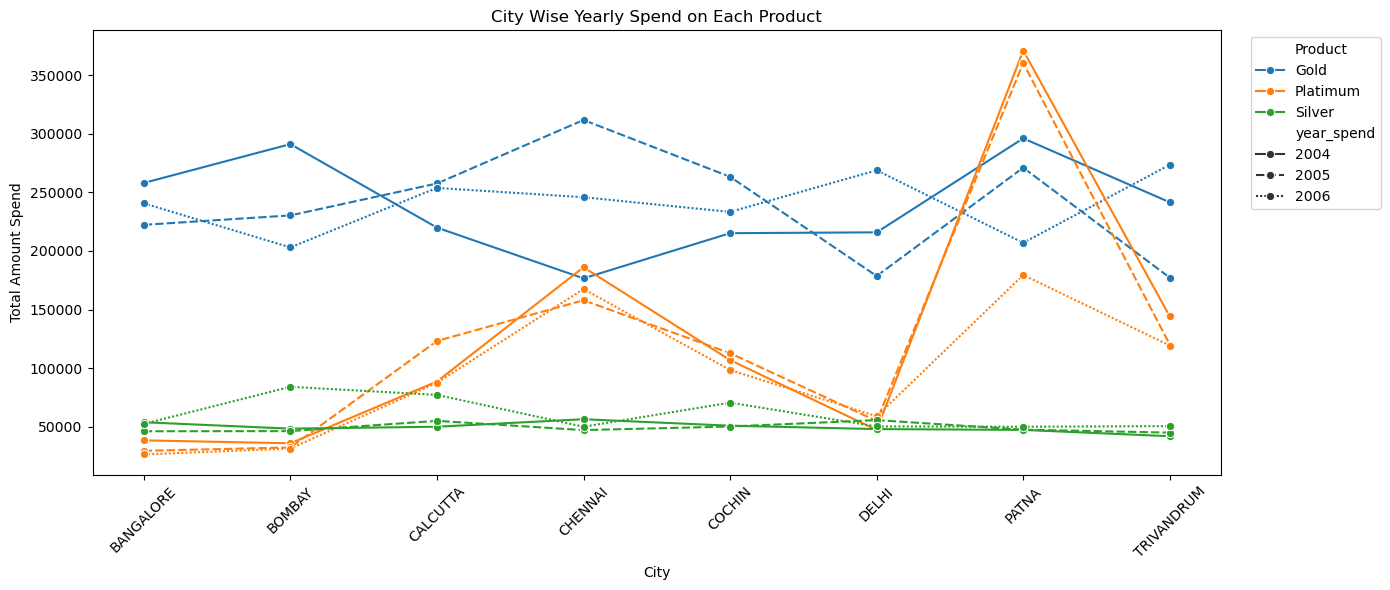

In [187]:
# 3. Calculate the city wise spend on each product on yearly basis. Also include a graphical representation for the same.
spend_c["year_spend"] = spend_c["Month"].dt.year
year = spend_c.pivot_table(index=["City","year_spend"] , columns="Product",values="Amount",aggfunc="sum").reset_index()

y=year.melt(
    id_vars=["City", "year_spend"],
    var_name="Product",
    value_name="Amount_spend"
)
plt.figure(figsize=(14,6))

sns.lineplot(
    data=y,
    x="City",
    y="Amount_spend",
    hue="Product",
    style="year_spend",
    marker="o"
)

plt.title("City Wise Yearly Spend on Each Product")
plt.xlabel("City")
plt.ylabel("Total Amount Spend")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# 4. Create graphs for


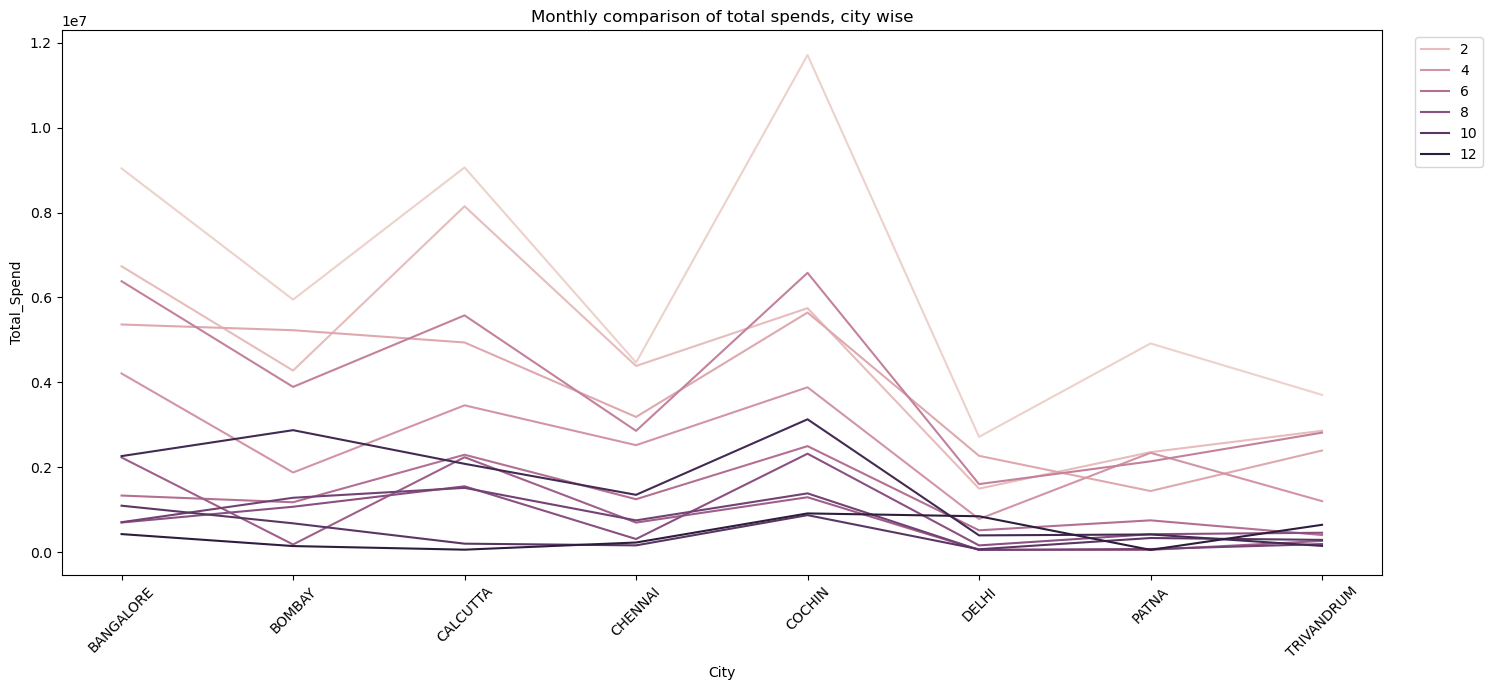

In [188]:
# a. Monthly comparison of total spends, city wise
y = spend_c.groupby(["Mo_spend","City"])["Amount"].sum().reset_index().round(2)


plt.figure(figsize=(15,7))
sns.lineplot(data=y , x = "City" , y ="Amount" , hue="Mo_spend")

plt.title("Monthly comparison of total spends, city wise")
plt.xlabel("City")
plt.ylabel("Total_Spend")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

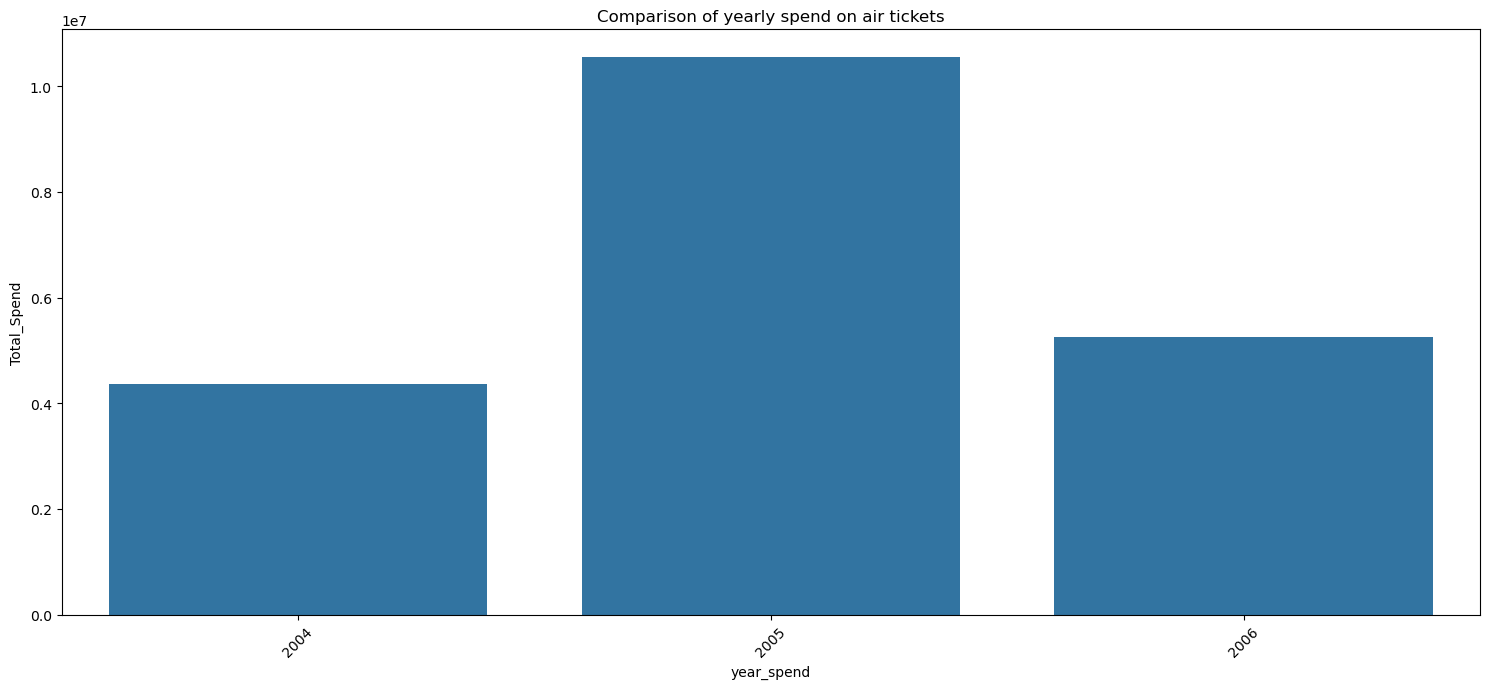

In [199]:
# b. Comparison of yearly spend on air tickets
h = spend_c.loc[spend_c["Type"] == "AIR TICKET"]
c = h.groupby("year_spend")["Amount"].sum().reset_index().round(1)

plt.figure(figsize=(15,7))
sns.barplot(data=c , x = "year_spend" , y = "Amount")

plt.title("Comparison of yearly spend on air tickets")
plt.xlabel("year_spend")
plt.ylabel("Total_Spend")
plt.xticks(rotation=45)
#plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

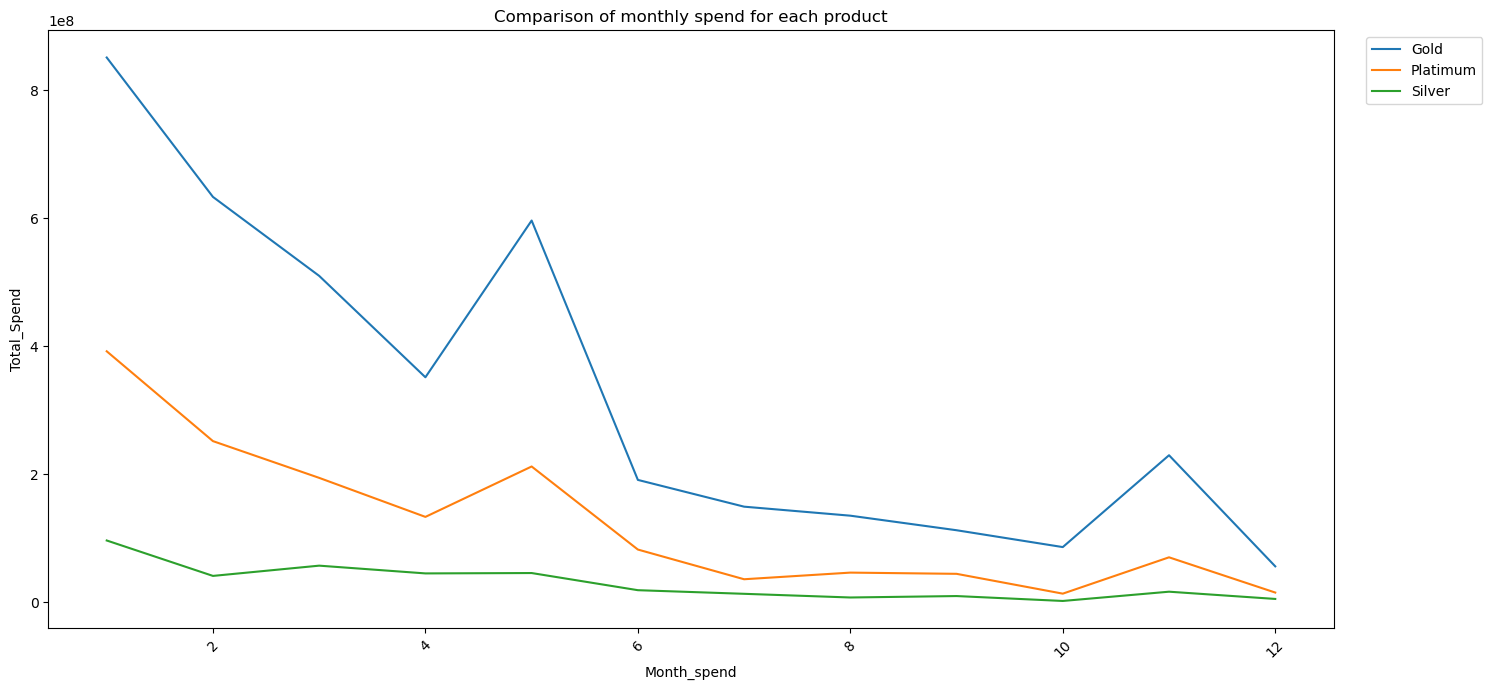

In [155]:
#c. Comparison of monthly spend for each product (look for any seasonality that exists in terms of spend)
d = final.groupby(["Mo_spend","Product"])["Amount_spend"].sum().reset_index()

plt.figure(figsize=(15,7))
sns.lineplot(data = d , x = "Mo_spend" , y = "Amount_spend" , hue="Product" )

plt.title("Comparison of monthly spend for each product")
plt.xlabel("Month_spend")
plt.ylabel("Total_Spend")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [ ]:
#5. Write user defined PYTHON function to perform the following analysis:
#You need to find top 10 customers for each city in terms of their repayment amount by 
#different products and by different time periods i.e. year or month. The user should be able 
#to specify the product (Gold/Silver/Platinum) and time period (yearly or monthly) and the 
#function should automatically take these inputs while identifying the top 10 customers

In [196]:
def top_10_customer(product, period):

    df = repay_c.copy()

    df["Month_repayment"] = pd.to_datetime(
        df["Month"], errors="coerce"
    )

    # Product filter
    df = df[df["Product"].str.upper() == product.upper()]

    # Time period
    if period.lower() == "yearly":
        df["Time"] = df["Month"].dt.year

    elif period.lower() == "monthly":
        df["Time"] = df["Month"].dt.to_period("M")

    else:
        return "Please enter yearly or monthly"

    # Groupby
    result = (
        df.groupby(["City", "Time", "Customer"])["Amount"]
        .sum()
        .reset_index()
    )

    # Top 10
    result = (
        result.sort_values("Amount", ascending=False)
        .groupby(["City", "Time"])
        .head(10)
        .reset_index(drop=True)
    )

    return result

In [197]:
top_10_customer("Gold", "yearly")

,City,Time,Customer,Amount
0,COCHIN,2005,A61,4276860.55
1,DELHI,2005,A44,4165317.77
2,COCHIN,2005,A45,4042447.57
3,BANGALORE,2005,A43,4006956.60
4,BANGALORE,2005,A13,3757673.00
...,...,...,...,...
83,BANGALORE,2006,A88,146821.30
84,PATNA,2006,A66,113094.58
85,COCHIN,2006,A90,109931.32
86,CHENNAI,2004,A67,67845.60


(37284, 17)